Active Threads: 8
Running O(N) exact scaling for N = 10:100 (M=1000)...
N= 10 | Low: q_EA= 0.883, peaks= 1.00, uniq=  34 | High: q_EA= 0.333, peaks= 3.51, uniq= 774
N= 20 | Low: q_EA= 0.868, peaks= 1.00, uniq= 816 | High: q_EA= 0.135, peaks= 7.99, uniq=1000
N= 30 | Low: q_EA= 0.937, peaks= 1.00, uniq=1000 | High: q_EA= 0.068, peaks=12.50, uniq=1000
N= 40 | Low: q_EA= 0.945, peaks= 1.00, uniq=1000 | High: q_EA= 0.054, peaks=16.89, uniq=1000
N= 50 | Low: q_EA= 0.961, peaks= 1.00, uniq=1000 | High: q_EA= 0.043, peaks=21.43, uniq=1000
N= 60 | Low: q_EA= 0.954, peaks= 1.00, uniq=1000 | High: q_EA= 0.038, peaks=26.32, uniq=1000
N= 70 | Low: q_EA= 0.974, peaks= 1.00, uniq=1000 | High: q_EA= 0.031, peaks=30.26, uniq=1000
N= 80 | Low: q_EA= 0.968, peaks= 1.00, uniq=1000 | High: q_EA= 0.024, peaks=34.59, uniq=1000
N= 90 | Low: q_EA= 0.978, peaks= 1.00, uniq=1000 | High: q_EA= 0.022, peaks=39.60, uniq=1000
N=100 | Low: q_EA= 0.981, peaks= 1.00, uniq=1000 | High: q_EA= 0.021, peaks=44.24, uniq=100

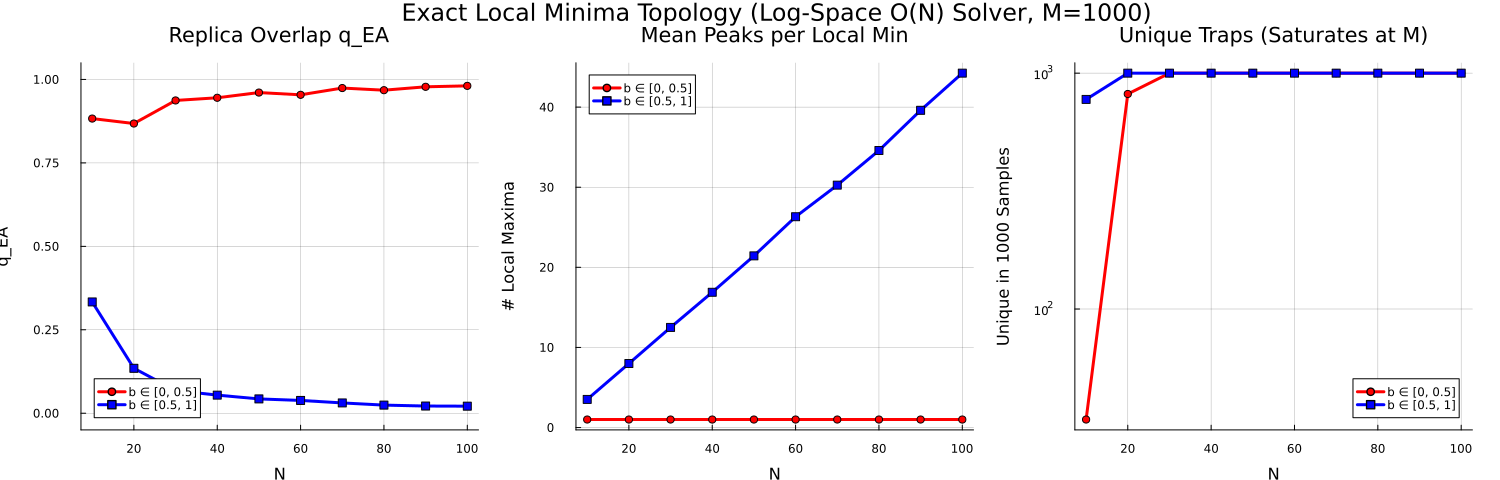


Sweeping frustration fraction f for N=50 (5 disorder samples x 1000 walkers)...
f = 0.00 | q_EA = 0.947 ± 0.012 | Mean Peaks = 1.00
f = 0.05 | q_EA = 0.804 ± 0.082 | Mean Peaks = 3.24
f = 0.10 | q_EA = 0.659 ± 0.060 | Mean Peaks = 5.36
f = 0.15 | q_EA = 0.478 ± 0.097 | Mean Peaks = 7.80
f = 0.20 | q_EA = 0.404 ± 0.092 | Mean Peaks = 10.05
f = 0.25 | q_EA = 0.390 ± 0.064 | Mean Peaks = 10.94
f = 0.30 | q_EA = 0.270 ± 0.056 | Mean Peaks = 13.71
f = 0.35 | q_EA = 0.149 ± 0.052 | Mean Peaks = 16.27
f = 0.40 | q_EA = 0.115 ± 0.044 | Mean Peaks = 17.24
f = 0.45 | q_EA = 0.075 ± 0.027 | Mean Peaks = 18.78
f = 0.50 | q_EA = 0.080 ± 0.013 | Mean Peaks = 18.25
f = 0.55 | q_EA = 0.104 ± 0.047 | Mean Peaks = 17.99
f = 0.60 | q_EA = 0.064 ± 0.013 | Mean Peaks = 18.92
f = 0.65 | q_EA = 0.063 ± 0.012 | Mean Peaks = 18.85
f = 0.70 | q_EA = 0.061 ± 0.014 | Mean Peaks = 18.78
f = 0.75 | q_EA = 0.054 ± 0.004 | Mean Peaks = 20.21
f = 0.80 | q_EA = 0.051 ± 0.004 | Mean Peaks = 19.08
f = 0.85 | q_EA = 0.04

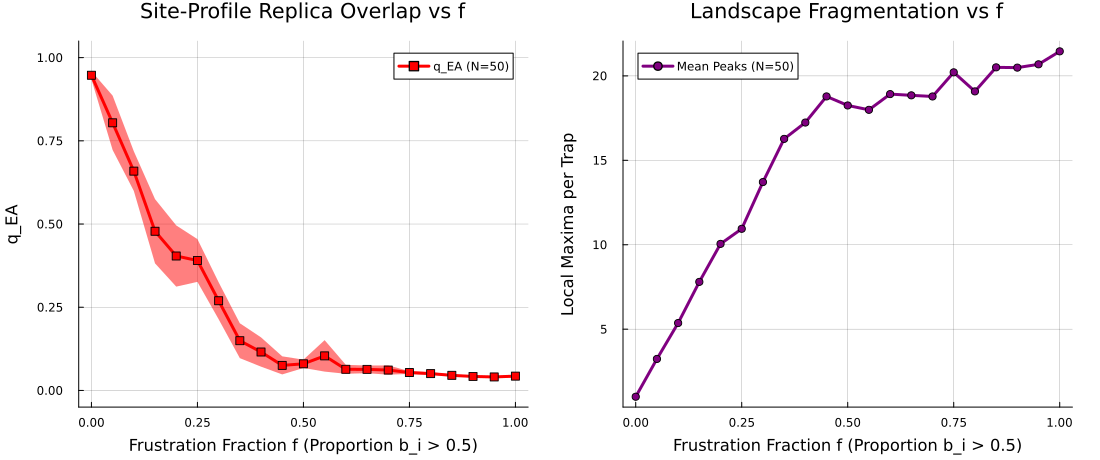

In [ ]:
ENV["GKSwstype"] = "100"
using Plots
using Plots.PlotMeasures
using Random
using Printf
using Statistics
using Base.Threads

figures_dir = joinpath(@__DIR__, "figures", "spin_glass_barriers")
mkpath(figures_dir)
println("Active Threads: ", nthreads())

const LOG2 = log(2.0)

# ==============================================================================
# 1. Exact Log-Space MFPT (Eq. 40) & O(N^2) Mirror-Symmetric Descent (Eq. 80)
# ==============================================================================
@inline function logaddexp(a::Float64, b::Float64)
    a == -Inf && return b
    b == -Inf && return a
    m = max(a, b)
    d = abs(a - b)
    return d > 37.0 ? m : m + log1p(exp(-d))
end

@inline function logsubexp(hi::Float64, lo::Float64)
    lo == -Inf && return hi
    d = hi - lo
    return d > 37.0 ? hi : hi + log(-expm1(-d))
end

function calc_log_T0(log_x::Vector{Float64}, p::Vector{Int})
    K = length(p)
    log_L = log_x[p[1]]
    log_sum = log_L
    @inbounds for k in 2:K
        log_L = log_x[p[k]] + logaddexp(0.0, log_L)
        log_sum = logaddexp(log_sum, log_L)
    end
    return logaddexp(log(Float64(K + 1)), LOG2 + log_sum)
end

function sym_sweep_lr!(
    p::Vector{Int},
    b_base::Vector{Float64},
    log_x::Vector{Float64},
    log_L::Vector{Float64},
    log_R::Vector{Float64},
)
    K = length(p)
    swaps = 0
    @inbounds for y in 1:(K - 1)
        iy  = p[y]
        iy1 = p[y + 1]
        Ly  = (y == 1) ? -Inf : log_L[y - 1]
        Ry  = (y == K - 1) ? -Inf : log_R[y + 2]

        if isfinite(Ly) || isfinite(Ry)
            if abs(Ly - Ry) > 1e-12
                if (b_base[iy] > b_base[iy1] && Ly < Ry) || (b_base[iy] < b_base[iy1] && Ly > Ry)
                    p[y] = iy1
                    p[y + 1] = iy
                    iy = iy1
                    swaps += 1
                end
            end
        end
        log_L[y] = (y == 1) ? log_x[iy] : log_x[iy] + logaddexp(0.0, log_L[y - 1])
    end
    return swaps
end

function sym_sweep_rl!(
    p::Vector{Int},
    b_base::Vector{Float64},
    log_x::Vector{Float64},
    log_L::Vector{Float64},
    log_R::Vector{Float64},
)
    K = length(p)
    swaps = 0
    @inbounds for y in (K - 1):-1:1
        iy  = p[y]
        iy1 = p[y + 1]
        Ly  = (y == 1) ? -Inf : log_L[y - 1]
        Ry  = (y == K - 1) ? -Inf : log_R[y + 2]

        if isfinite(Ly) || isfinite(Ry)
            if abs(Ly - Ry) > 1e-12
                if (b_base[iy] > b_base[iy1] && Ly < Ry) || (b_base[iy] < b_base[iy1] && Ly > Ry)
                    p[y] = iy1
                    p[y + 1] = iy
                    iy1 = iy
                    swaps += 1
                end
            end
        end
        log_R[y + 1] = (y == K - 1) ? log_x[iy1] : log_x[iy1] + logaddexp(0.0, log_R[y + 2])
    end
    return swaps
end

function sym_adjacent_descent(
    b_base::Vector{Float64},
    log_x::Vector{Float64},
    p_start::Vector{Int},
    start_lr::Bool,
)
    K = length(b_base)
    p = copy(p_start)
    log_L = Vector{Float64}(undef, K)
    log_R = Vector{Float64}(undef, K)

    if start_lr
        log_R[K] = log_x[p[K]]
        @inbounds for m in (K - 1):-1:1
            log_R[m] = log_x[p[m]] + logaddexp(0.0, log_R[m + 1])
        end
        for _ in 1:(4 * K)
            sym_sweep_lr!(p, b_base, log_x, log_L, log_R) == 0 && break
            sym_sweep_rl!(p, b_base, log_x, log_L, log_R) == 0 && break
        end
    else
        log_L[1] = log_x[p[1]]
        @inbounds for m in 2:(K - 1)
            log_L[m] = log_x[p[m]] + logaddexp(0.0, log_L[m - 1])
        end
        for _ in 1:(4 * K)
            sym_sweep_rl!(p, b_base, log_x, log_L, log_R) == 0 && break
            sym_sweep_lr!(p, b_base, log_x, log_L, log_R) == 0 && break
        end
    end
    return p
end

# ==============================================================================
# 2. Distances & Greedy Minimax Geodesic Barrier Estimator
# ==============================================================================
function kendall_tau_norm(p1::Vector{Int}, p2::Vector{Int})
    K = length(p1)
    pos2 = Vector{Int}(undef, K)
    @inbounds for i in 1:K
        pos2[p2[i]] = i
    end
    inv_count = 0
    @inbounds for i in 1:(K - 1)
        pi_pos = pos2[p1[i]]
        for j in (i + 1):K
            if pi_pos > pos2[p1[j]]
                inv_count += 1
            end
        end
    end
    return inv_count / (K * (K - 1) / 2.0)
end

function geodesic_barrier_oneway(
    log_x::Vector{Float64},
    x_val::Vector{Float64},
    p1::Vector{Int},
    p2::Vector{Int},
    lt1::Float64,
    lt2::Float64,
)
    K = length(p1)
    log_N = log(Float64(K + 1))
    pos2 = Vector{Int}(undef, K)
    @inbounds for i in 1:K
        pos2[p2[i]] = i
    end

    p = copy(p1)
    log_L = Vector{Float64}(undef, K)
    log_R = Vector{Float64}(undef, K)
    max_lt = max(lt1, lt2)

    while true
        # Single O(K) forward pass yields both log_L and exact current log(T_0)
        log_L[1] = log_x[p[1]]
        log_sum = log_L[1]
        @inbounds for k in 2:K
            log_L[k] = log_x[p[k]] + logaddexp(0.0, log_L[k - 1])
            log_sum = logaddexp(log_sum, log_L[k])
        end
        cur_lt = logaddexp(log_N, LOG2 + log_sum)
        if cur_lt > max_lt
            max_lt = cur_lt
        end

        # Single O(K) backward pass yields log_R
        log_R[K] = log_x[p[K]]
        @inbounds for k in (K - 1):-1:1
            log_R[k] = log_x[p[k]] + logaddexp(0.0, log_R[k + 1])
        end

        # Evaluate all geodesic-eligible adjacent swaps in O(K) via Eq. (80)
        best_down_y = 0
        best_down_gain = -Inf
        best_up_y = 0
        best_up_cost = Inf

        @inbounds for y in 1:(K - 1)
            iy  = p[y]
            iy1 = p[y + 1]
            if pos2[iy] > pos2[iy1]
                Ly = (y == 1) ? -Inf : log_L[y - 1]
                Ry = (y == K - 1) ? -Inf : log_R[y + 2]
                dx = x_val[iy1] - x_val[iy]

                if (!isfinite(Ly) && !isfinite(Ry)) || abs(Ly - Ry) <= 1e-12 || dx == 0.0
                    if best_up_cost > -Inf
                        best_up_y = y
                        best_up_cost = -Inf
                    end
                else
                    is_down = (dx > 0.0 && Ly < Ry) || (dx < 0.0 && Ly > Ry)
                    hi, lo = (Ly > Ry) ? (Ly, Ry) : (Ry, Ly)
                    log_mag = log(abs(dx)) + logsubexp(hi, lo)
                    if is_down
                        if log_mag > best_down_gain
                            best_down_gain = log_mag
                            best_down_y = y
                        end
                    else
                        if log_mag < best_up_cost
                            best_up_cost = log_mag
                            best_up_y = y
                        end
                    end
                end
            end
        end

        y_move = (best_down_y != 0) ? best_down_y : best_up_y
        y_move == 0 && break
        p[y_move], p[y_move + 1] = p[y_move + 1], p[y_move]
    end

    return max(0.0, max_lt - max(lt1, lt2))
end

function geodesic_barrier(
    log_x::Vector{Float64},
    x_val::Vector{Float64},
    p1::Vector{Int},
    p2::Vector{Int},
    lt1::Float64,
    lt2::Float64,
)
    b12 = geodesic_barrier_oneway(log_x, x_val, p1, p2, lt1, lt2)
    b21 = geodesic_barrier_oneway(log_x, x_val, p2, p1, lt2, lt1)
    return min(b12, b21)
end

# ==============================================================================
# 3. Single-Disorder Landscape Analyzer
# ==============================================================================
function sample_maximal_support(rng::AbstractRNG, K::Int, mu::Float64)
    lo = max(0.0, 2.0 * mu - 1.0)
    hi = min(1.0, 2.0 * mu)
    return clamp.(lo .+ rand(rng, K) .* (hi - lo), 1e-9, 1.0 - 1e-9)
end

function analyze_realization(
    b_base::Vector{Float64};
    n_traps::Int=120,
    n_pairs::Int=120,
    n_rand::Int=200,
    seed::Int=1000,
)
    K = length(b_base)
    x_val = (1.0 .- b_base) ./ b_base
    log_x = log.(x_val)
    S_base = (b_base .- mean(b_base)) ./ std(b_base, corrected=false)

    # 1. Reference energy scale: <ln T_0>_rand
    rand_lts = Vector{Float64}(undef, n_rand)
    @threads for r in 1:n_rand
        rng_r = Xoshiro(seed + 10_000 + r)
        rand_lts[r] = calc_log_T0(log_x, shuffle(rng_r, 1:K))
    end
    mean_rand_lt = mean(rand_lts)

    # 2. Discover local minima via exact adjacent-swap descent
    traps = Vector{Vector{Int}}(undef, n_traps)
    trap_lts = Vector{Float64}(undef, n_traps)
    @threads for s in 1:n_traps
        rng_s = Xoshiro(seed + s)
        p = sym_adjacent_descent(b_base, log_x, shuffle(rng_s, 1:K), rand(rng_s, Bool))
        traps[s] = p
        trap_lts[s] = calc_log_T0(log_x, p)
    end

    lt_min = minimum(trap_lts)
    span = max(mean_rand_lt - lt_min, 1e-12)
    eps_vals = (trap_lts .- lt_min) ./ span

    # 3. Sample random distinct pairs (alpha, beta) for distances & barriers
    rng_p = Xoshiro(seed + 50_000)
    pair_i = Vector{Int}(undef, n_pairs)
    pair_j = Vector{Int}(undef, n_pairs)
    for m in 1:n_pairs
        i = rand(rng_p, 1:n_traps)
        j = rand(rng_p, 1:(n_traps - 1))
        j >= i && (j += 1)
        pair_i[m] = i
        pair_j[m] = j
    end

    q_pairs    = Vector{Float64}(undef, n_pairs)
    kt_pairs   = Vector{Float64}(undef, n_pairs)
    braw_pairs = Vector{Float64}(undef, n_pairs)

    @threads for m in 1:n_pairs
        i = pair_i[m]
        j = pair_j[m]
        pi = traps[i]
        pj = traps[j]
        q_sum = 0.0
        @inbounds for k in 1:K
            q_sum += S_base[pi[k]] * S_base[pj[k]]
        end
        q_pairs[m] = q_sum / K
        kt_pairs[m] = kendall_tau_norm(pi, pj)
        braw_pairs[m] = geodesic_barrier(log_x, x_val, pi, pj, trap_lts[i], trap_lts[j])
    end

    bnorm_pairs = braw_pairs ./ span
    return (
        span = span,
        eps = eps_vals,
        q = q_pairs,
        kt = kt_pairs,
        braw = braw_pairs,
        bnorm = bnorm_pairs,
    )
end

# Helper for binned median curves in scatter plots
function binned_medians(x::Vector{Float64}, y::Vector{Float64}; nbins::Int=10)
    lo, hi = extrema(x)
    hi <= lo && return Float64[], Float64[]
    edges = range(lo, hi, length=nbins + 1)
    xs = Float64[]; ys = Float64[]
    for b in 1:nbins
        mask = (b == nbins) ? ((x .>= edges[b]) .& (x .<= edges[b + 1])) :
                              ((x .>= edges[b]) .& (x .< edges[b + 1]))
        if count(mask) >= 10
            push!(xs, 0.5 * (edges[b] + edges[b + 1]))
            push!(ys, median(y[mask]))
        end
    end
    return xs, ys
end

# ==============================================================================
# 4. Figure 1: Three-Phase Comparison (Ordered, Coexistence, Shattered)
# ==============================================================================
function run_three_phase_comparison(;
    N::Int=40,
    n_disorder::Int=8,
    n_traps::Int=120,
    n_pairs::Int=150,
)
    K = N - 1
    phases = [
        (mu = 0.20, label = "Phase I: Ordered (μ=0.20)",     color = :royalblue),
        (mu = 0.40, label = "Phase II: Coexistence (μ=0.40)", color = :darkorange),
        (mu = 0.75, label = "Phase III: Shattered (μ=0.75)",  color = :crimson),
    ]

    rng = Xoshiro(42)
    p1 = plot(title="Pairwise Replica Overlap P(q)", xlabel="Site-Profile Overlap q_{αβ}",
              ylabel="Probability Density", xlims=(-0.6, 1.05), gridalpha=0.3, legend=:topleft)
    p2 = plot(title="Normalized Trap Depth P(ε)", xlabel="ε = (ln T₀ - ln T₀^min) / ΔE_land",
              ylabel="Probability Density", xlims=(0.0, 0.45), gridalpha=0.3, legend=:topright)
    p3 = plot(title="Normalized Saddle Barrier P(B_norm)", xlabel="B_norm = B_raw / ΔE_land",
              ylabel="Probability Density", xlims=(0.0, 1.25), gridalpha=0.3, legend=:topright)
    p4 = plot(title="Barrier Height vs. Profile Distance", xlabel="Profile Distance (1 - q_{αβ})",
              ylabel="Normalized Barrier B_norm", xlims=(0.0, 1.5), ylims=(-0.02, 1.25),
              gridalpha=0.3, legend=:topleft)

    println("=== Figure 1: Three-Phase Landscape Depth & Distance (N=$N, $n_disorder realizations) ===")
    for (pi, ph) in enumerate(phases)
        all_q = Float64[]; all_kt = Float64[]; all_eps = Float64[]
        all_braw = Float64[]; all_bnorm = Float64[]; all_span = Float64[]

        for r in 1:n_disorder
            b_base = sample_maximal_support(rng, K, ph.mu)
            res = analyze_realization(b_base; n_traps=n_traps, n_pairs=n_pairs,
                                      seed=100_000 * pi + 1_000 * r)
            append!(all_q, res.q)
            append!(all_kt, res.kt)
            append!(all_eps, res.eps)
            append!(all_braw, res.braw)
            append!(all_bnorm, res.bnorm)
            push!(all_span, res.span)
        end

        @printf("%-31s | span=%5.2f | q̄=%5.3f | d_KT=%5.3f | ⟨ε⟩=%5.3f | med(B_raw)=%6.4f | med(B_norm)=%5.3f\n",
                ph.label, mean(all_span), mean(all_q), mean(all_kt), mean(all_eps),
                median(all_braw), median(all_bnorm))

        histogram!(p1, all_q, bins=range(-0.6, 1.0, length=42), normalize=:pdf,
                   alpha=0.40, color=ph.color, lc=ph.color, lw=1.2, label=ph.label)
        histogram!(p2, clamp.(all_eps, 0.0, 0.45), bins=range(0.0, 0.45, length=38), normalize=:pdf,
                   alpha=0.40, color=ph.color, lc=ph.color, lw=1.2, label=ph.label)
        histogram!(p3, clamp.(all_bnorm, 0.0, 1.25), bins=range(0.0, 1.25, length=40), normalize=:pdf,
                   alpha=0.40, color=ph.color, lc=ph.color, lw=1.2, label=ph.label)

        # Scatter subsample + binned median trendline
        dist_prof = 1.0 .- all_q
        sub = 1:min(350, length(dist_prof))
        scatter!(p4, dist_prof[sub], clamp.(all_bnorm[sub], 0.0, 1.25),
                 color=ph.color, alpha=0.18, ms=2.5, msw=0, label="")
        bx, by = binned_medians(dist_prof, all_bnorm; nbins=10)
        plot!(p4, bx, by, lw=3.0, color=ph.color, marker=:circle, ms=4, label=ph.label)
    end

    p_fig1 = plot(p1, p2, p3, p4, layout=(2, 2), size=(1350, 920), margin=5Plots.mm,
                  plot_title="Local Minima Depth, Barriers & Separation Across the Three Phases (N = $N)",
                  plot_titlefontsize=13)
    out1 = joinpath(figures_dir, "landscape_depth_distance_3phases_N$(N).pdf")
    savefig(p_fig1, out1)
    display(p_fig1)
    println("Saved Figure 1 to ", out1)
end

# ==============================================================================
# 5. Figure 2: Continuous Sweep Across mu in [0.10, 0.90]
# ==============================================================================
function run_mu_barrier_sweep(;
    N::Int=40,
    mu_vals::Vector{Float64}=collect(range(0.10, 0.90, length=17)),
    n_disorder::Int=6,
    n_traps::Int=80,
    n_pairs::Int=80,
)
    K = N - 1
    n_mu = length(mu_vals)
    rng = Xoshiro(2026)

    dprof_m = zeros(n_mu); dprof_s = zeros(n_mu)
    dkt_m   = zeros(n_mu); dkt_s   = zeros(n_mu)
    eps_m   = zeros(n_mu); eps_s   = zeros(n_mu)
    bnorm_m = zeros(n_mu); bnorm_s = zeros(n_mu)
    braw_m  = zeros(n_mu); braw_s  = zeros(n_mu)
    span_m  = zeros(n_mu); span_s  = zeros(n_mu)

    println("\n=== Figure 2: Continuous μ-Sweep of Barriers & Distances (N=$N) ===")
    for (mi, mu) in enumerate(mu_vals)
        dp = Float64[]; dk = Float64[]; ep = Float64[]
        bn = Float64[]; br = Float64[]; sp = Float64[]

        for r in 1:n_disorder
            b_base = sample_maximal_support(rng, K, mu)
            res = analyze_realization(b_base; n_traps=n_traps, n_pairs=n_pairs,
                                      seed=900_000 + 10_000 * mi + 100 * r)
            push!(dp, 1.0 - mean(res.q))
            push!(dk, mean(res.kt))
            push!(ep, mean(res.eps))
            push!(bn, median(res.bnorm))
            push!(br, median(res.braw))
            push!(sp, res.span)
        end

        dprof_m[mi] = mean(dp); dprof_s[mi] = std(dp)
        dkt_m[mi]   = mean(dk); dkt_s[mi]   = std(dk)
        eps_m[mi]   = mean(ep); eps_s[mi]   = std(ep)
        bnorm_m[mi] = mean(bn); bnorm_s[mi] = std(bn)
        braw_m[mi]  = mean(br); braw_s[mi]  = std(br)
        span_m[mi]  = mean(sp); span_s[mi]  = std(sp)

        @printf("μ=%.2f | 1-q̄=%.3f | d_KT=%.3f | ⟨ε⟩=%.3f | B_norm=%.3f | B_raw=%.4f | ΔE_land=%.2f\n",
                mu, dprof_m[mi], dkt_m[mi], eps_m[mi], bnorm_m[mi], braw_m[mi], span_m[mi])
    end

    # Save numerical table
    tsv_path = joinpath(figures_dir, "barrier_sweep_N$(N).tsv")
    open(tsv_path, "w") do io
        println(io, "mu\td_prof\td_kt\teps\tB_norm\tB_raw\tspan")
        for mi in 1:n_mu
            @printf(io, "%.4f\t%.6f\t%.6f\t%.6f\t%.6f\t%.6f\t%.6f\n",
                    mu_vals[mi], dprof_m[mi], dkt_m[mi], eps_m[mi], bnorm_m[mi], braw_m[mi], span_m[mi])
        end
    end

    p1 = plot(mu_vals, dprof_m, ribbon=dprof_s, fillalpha=0.18, lw=2.5, color=:crimson, marker=:circle, ms=3.5,
              label="Profile Distance (1 - q̄)", title="Separation Between Minima",
              xlabel="Mean Weight μ", ylabel="Normalized Distance", ylims=(-0.05, 1.15), gridalpha=0.3, legend=:topleft)
    plot!(p1, mu_vals, dkt_m, ribbon=dkt_s, fillalpha=0.18, lw=2.2, ls=:dash, color=:slategray, marker=:square, ms=3,
          label="Swap Distance (d_KT)")

    p2 = plot(mu_vals, bnorm_m, ribbon=bnorm_s, fillalpha=0.18, lw=2.5, color=:purple, marker=:diamond, ms=3.5,
              label="Median Barrier B_norm", title="Dimensionless Ruggedness & Trap Depth",
              xlabel="Mean Weight μ", ylabel="Fraction of ΔE_land", ylims=(-0.05, 0.85), gridalpha=0.3, legend=:topleft)
    plot!(p2, mu_vals, eps_m, ribbon=eps_s, fillalpha=0.18, lw=2.5, color=:darkorange, marker=:circle, ms=3.5,
          label="Mean Trap Excess ⟨ε⟩")

    p3 = plot(mu_vals, span_m, ribbon=span_s, fillalpha=0.18, lw=2.5, color=:royalblue, marker=:square, ms=3.5,
              label="Landscape Span ΔE_land", title="Absolute Log-MFPT Scale (Sinai Peak)",
              xlabel="Mean Weight μ", ylabel="Log-MFPT Units ln(T_a / T_b)", gridalpha=0.3, legend=:topright)
    plot!(p3, mu_vals, braw_m, ribbon=braw_s, fillalpha=0.18, lw=2.5, color=:crimson, marker=:circle, ms=3.5,
          label="Median Raw Barrier B_raw")

    for plt in (p1, p2, p3)
        vline!(plt, [0.25], color=:black, ls=:dash, lw=1.2, alpha=0.6, label="")
        vline!(plt, [0.50], color=:black, ls=:dot,  lw=1.5, alpha=0.7, label="")
    end

    p_fig2 = plot(p1, p2, p3, layout=(1, 3), size=(1550, 480), margin=5Plots.mm,
                  plot_title="Landscape Separation, Trap Depth & Barriers vs. μ (N = $N; Lines: μ = 0.25, 0.50)",
                  plot_titlefontsize=12)
    out2 = joinpath(figures_dir, "landscape_depth_distance_vs_mu_N$(N).pdf")
    savefig(p_fig2, out2)
    display(p_fig2)
    println("Saved Figure 2 to ", out2)
end

run_three_phase_comparison(N=40, n_disorder=8, n_traps=120, n_pairs=150)
run_mu_barrier_sweep(N=40, n_disorder=6, n_traps=80, n_pairs=80)